# Pilot: Brassicaceae LC-MS/MS annotations vs PlantMetWiki metabolites

**Question.** How many metabolites annotated in the Brassicaceae metabolic fingerprinting dataset
(Wolters et al. 2026, Zenodo [10.5281/zenodo.19391098](https://doi.org/10.5281/zenodo.19391098))
are present as metabolites in [PlantMetWiki](https://plantmetwiki.bioinformatics.nl)?
Which pathways do they cover, and is it mostly primary or specialized metabolism?

This is the first test of evidence case 3 (*consensus from MS/MS tools*) in the main [README](../../README.md).

**Approach.**
- For each LC-MS/MS feature, we take every structure prediction: the GNPS library match, Felicia's consensus structure, and the SIRIUS, MS2Query and DreaMS top hits.
- Each prediction gets an **evidence tier**.
- Predictions are compared to PlantMetWiki metabolites on the **first InChIKey block** (atom connectivity). Stereochemistry and charge are ignored, because PlantMetWiki often stores charged forms (carboxylates, sulfonates) while MS tools predict neutral structures.

All matching logic is in [`match_plantmetwiki.py`](match_plantmetwiki.py). This notebook calls `build()` and interprets the results.
Numbers quoted in the text are computed in the cells, so they update if the inputs change.

## How to reproduce

```bash
cd pilots/metabolomics_overlap
uv venv --python 3.12 .venv
uv pip install --python .venv/bin/python -r requirements.txt   # pinned versions
```

Then open this notebook in VS Code, select the `.venv` kernel and **Run All**. From the command line:
`.venv/bin/jupyter nbconvert --to notebook --execute --inplace explore_results.ipynb`.

The inputs are handled as follows:

| Input | How it is obtained | Frozen? |
|---|---|---|
| Annotated node tables (Zenodo S6) | downloaded automatically, MD5 checked against the Zenodo record | yes (Zenodo v1.0) |
| PlantMetWiki metabolites, pathway membership, pathway classes | SPARQL queries in `match_plantmetwiki.py`, saved as `data/plantmetwiki_*.csv` | yes: snapshot of 2026-09-29, committed to git |
| Pathway class → primary/specialized mapping | curated by hand: `data/pathway_class_categories.csv` | yes: committed to git |

To update to the live PlantMetWiki, delete `data/plantmetwiki_*.csv` and re-run. The snapshots are then re-queried, and the results may change.

## 1. Setup and provenance

In [1]:
import platform
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import rdkit
from IPython.display import Markdown, display

import match_plantmetwiki as m

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)

def say(text):
    """Render a Markdown sentence with computed numbers."""
    display(Markdown(text))

res = m.build()
pmw, pathways, tables, long, hits, per_met = (res[k] for k in ["pmw", "pathways", "tables", "long", "hits", "per_met"])
pathway_classes, metabolite_class = res["pathway_classes"], res["metabolite_class"]

TIERS = m.TIERS
DETECTION_TIERS = m.DETECTION_TIERS            # everything except MS2Query analogues
STRONG_TIERS = ["gnps_library", "consensus_inchi"]

In [2]:
# Software versions and input files used for this run
display(pd.Series({"python": platform.python_version(), "pandas": pd.__version__,
                   "rdkit": rdkit.__version__, "matplotlib": matplotlib.__version__}, name="version").to_frame())
m.snapshot_info()

,version
python,3.12.9
pandas,3.0.6
rdkit,2026.03.6
matplotlib,3.11.2


,size_MB,md5,last_modified
file,,,
data/plantmetwiki_metabolite_pathways.csv,1.42,fd6c2f38d8c5f5231227e46b80b55e59,2026-09-29 14:51
data/plantmetwiki_metabolites.csv,0.29,539084332fefd139fb10c5293dd3ac1b,2026-09-29 14:42
data/plantmetwiki_pathway_classes.csv,0.05,3284b2ca5f2cca48f7358188c8112ab0,2026-09-29 14:56
data/pathway_class_categories.csv,0.01,585e08d75da1a76318415fbbefab3316,2026-09-29 15:12
data/S6_Annotation_tables_and_annotated_FBMNs/14_LR_neg_full_FBMN_annotated_GNPS2_nodetable.csv,27.84,e8bd6de4407476197cdb2b5928723845,2026-09-29 15:20
data/S6_Annotation_tables_and_annotated_FBMNs/14_LR_pos_full_FBMN_annotated_GNPS2_nodetable.csv,33.25,e4fb450872d433119d7e079c80b7c8b4,2026-09-29 15:20


## 2. Evidence tiers

Each feature can carry up to six structure predictions. Each prediction is assigned an evidence tier, strongest first.

In [3]:
pd.DataFrame(
    [(i + 1, t, d, "strong" if t in STRONG_TIERS else ("not a detection" if t not in DETECTION_TIERS else "single tool"))
     for i, (t, d) in enumerate(m.TIER_DESCRIPTIONS.items())],
    columns=["rank", "tier", "meaning", "evidence strength"],
).set_index("rank")

,tier,meaning,evidence strength
rank,,,
1,gnps_library,GNPS spectral library match,strong
2,consensus_inchi,>= 2 of SIRIUS / MS2Query / DreaMS agree on the structure,strong
3,sirius,SIRIUS CSI:FingerID top hit,single tool
4,ms2query_exact,MS2Query hit with precursor m/z difference <= 0.01 Da,single tool
5,dreams,DreaMS top hit,single tool
6,ms2query_analog,"MS2Query analogue (different mass: related, NOT the same compound)",not a detection


**Comments**
- **Strong tiers.** A GNPS library match compares the spectrum with a reference spectrum of a known compound. Consensus means that at least 2 of 3 independent tools (SIRIUS, MS2Query, DreaMS) propose the same structure. We treat these two as *strong* evidence.
- **Single-tool tiers.** SIRIUS, MS2Query with exact mass, and DreaMS are each one tool's best guess.
- **MS2Query analogues.** An analogue has a different precursor mass, so it is a *related* compound, not the detected one. It never counts as a detection below.

## 3. Dataset overview

In [4]:
overview = pd.Series({
    "PlantMetWiki metabolites with InChIKey": res["pmw_raw"]["inchikey"].nunique(),
    "…distinct connectivity blocks (denominator for coverage)": len(pmw),
    "PlantCyc pathways in PlantMetWiki (single-reaction entries excluded)": pathways["plantcyc_id"].nunique(),
    **{f"LC-MS/MS features ({mode})": len(df) for mode, df in tables.items()},
    "PlantMetWiki metabolites detected (all detection tiers)": len(per_met),
    "PlantMetWiki metabolites detected (strong tiers)": per_met["best_tier"].isin(STRONG_TIERS).sum(),
}, name="count")
overview.to_frame()

,count
PlantMetWiki metabolites with InChIKey,2974
…distinct connectivity blocks (denominator for coverage),2732
PlantCyc pathways in PlantMetWiki (single-reaction entries excluded),1162
LC-MS/MS features (neg),6433
LC-MS/MS features (pos),7683
PlantMetWiki metabolites detected (all detection tiers),567
PlantMetWiki metabolites detected (strong tiers),139


**Comments**
- Coverage is measured against PlantMetWiki metabolites that have an InChIKey. About 10% of PlantMetWiki metabolites have none (often generic classes such as "a fatty acid"), so they can't be matched this way.
- Stereoisomers and charge variants share their first InChIKey block. Several PlantMetWiki entries can therefore collapse into one connectivity block, e.g. D- and L-tryptophan, or UDP-glucose and UDP-galactose.
- PlantMetWiki also types ~1,270 single-reaction diagrams (IDs like `ADENPHOSPHOR-RXN`) as `wp:Pathway`. We exclude them, which leaves exactly the 1,162 PlantCyc pathways reported in the PlantMetWiki paper.

## 4. Hit rate per evidence tier and ion mode

- *Features with prediction*: the number of features for which this tier proposes a structure.
- *In PlantMetWiki*: how many of those predicted structures are PlantMetWiki metabolites.

In [5]:
tier_table = (
    long.groupby(["tier", "mode"])
    .agg(features_with_prediction=("feature_id", "size"),
         in_plantmetwiki=("in_plantmetwiki", "sum"),
         distinct_pmw_metabolites=("key14", lambda s: s[long.loc[s.index, "in_plantmetwiki"]].nunique()))
    .reindex(pd.MultiIndex.from_product([TIERS, list(tables)], names=["tier", "mode"]))
)
tier_table["pct_in_plantmetwiki"] = (100 * tier_table["in_plantmetwiki"] / tier_table["features_with_prediction"]).round(1)
tier_table

features_with_prediction  in_plantmetwiki  distinct_pmw_metabolites  pct_in_plantmetwiki
tier            mode                                                                                          
gnps_library    neg                        172               67                        30                 39.0
                pos                        194               72                        38                 37.1
consensus_inchi neg                         57               30                        17                 52.6
                pos                        617              256                       107                 41.5
sirius          neg                       5186              190                        98                  3.7
                pos                       6954              399                       156                  5.7
ms2query_exact  neg                       1311              293                       135                 22.3
                pos                       2217              545                       203                 24.6
dreams          neg                       6433              561                       177                  8.7
                pos                       7683             1237                       327                 16.1
ms2query_analog neg                       5025              801                       184                 15.9
                pos                       5382              635                       150                 11.8

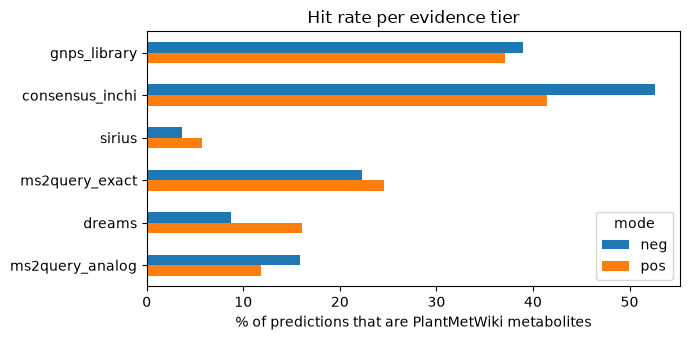

In [6]:
ax = tier_table["pct_in_plantmetwiki"].unstack("mode").reindex(TIERS).plot.barh(figsize=(7, 3.5))
ax.invert_yaxis()
ax.set_xlabel("% of predictions that are PlantMetWiki metabolites")
ax.set_ylabel("")
ax.set_title("Hit rate per evidence tier")
plt.tight_layout()

In [7]:
rate = tier_table.groupby(level="tier")[["features_with_prediction", "in_plantmetwiki"]].sum()
rate = (100 * rate["in_plantmetwiki"] / rate["features_with_prediction"]).round(1)
say(f"""**Findings (both modes combined)**
- Predictions with strong evidence are often PlantMetWiki metabolites: **{rate['gnps_library']}%** of GNPS library matches
  and **{rate['consensus_inchi']}%** of consensus structures.
- Single-tool predictions rarely are: SIRIUS **{rate['sirius']}%**, DreaMS **{rate['dreams']}%**,
  MS2Query (exact mass) **{rate['ms2query_exact']}%**.""")

**Findings (both modes combined)**
- Predictions with strong evidence are often PlantMetWiki metabolites: **38.0%** of GNPS library matches
  and **42.4%** of consensus structures.
- Single-tool predictions rarely are: SIRIUS **4.9%**, DreaMS **12.7%**,
  MS2Query (exact mass) **23.8%**.

**Interpretation**
- **Why strong tiers hit PlantMetWiki more often.** Spectral libraries and PlantCyc both favour well-known, well-studied compounds, and agreement between tools filters out many wrong guesses.
- **Why SIRIUS hits least often.** SIRIUS ranks candidates from very large structure databases, so its top hit is often a compound that is not in any plant pathway database, even when the compound class is right.
- **Why a low hit rate is not the same as "wrong".** Most specialized metabolites in a plant extract simply have no pathway in PlantCyc yet.
- **Why the MS2Query rate is misleading.** The exact-mass MS2Query hits have a high hit rate partly because the MS2Query library is itself built from known compounds.

## 5. Cumulative coverage of PlantMetWiki

Distinct PlantMetWiki metabolites detected in either ion mode, adding tiers from strongest to weakest.

In [8]:
rows, seen = [], set()
for tier in DETECTION_TIERS:
    new = set(hits.loc[hits["tier"] == tier, "key14"]) - seen
    seen |= new
    rows.append((tier, len(new), len(seen), round(100 * len(seen) / len(pmw), 1)))
cumulative = pd.DataFrame(rows, columns=["up to tier", "newly added", "distinct PlantMetWiki metabolites", "% of PlantMetWiki"]).set_index("up to tier")
analog_only = set(hits.loc[hits["tier"] == "ms2query_analog", "key14"]) - seen
cumulative

,newly added,distinct PlantMetWiki metabolites,% of PlantMetWiki
up to tier,,,
gnps_library,56,56,2.0
consensus_inchi,83,139,5.1
sirius,119,258,9.4
ms2query_exact,111,369,13.5
dreams,198,567,20.8


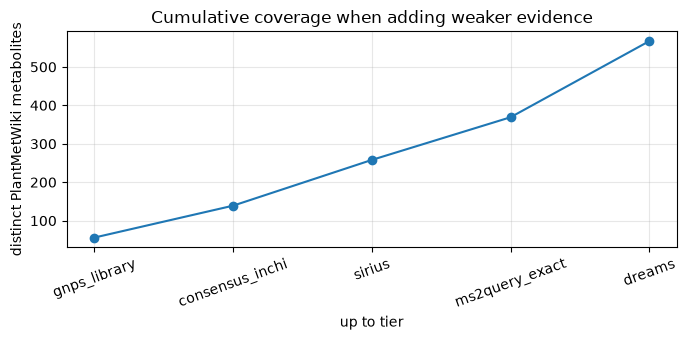

In [9]:
ax = cumulative["distinct PlantMetWiki metabolites"].plot(marker="o", figsize=(7, 3.5))
ax.set_xticks(range(len(cumulative)), cumulative.index, rotation=20)
ax.set_ylabel("distinct PlantMetWiki metabolites")
ax.set_title("Cumulative coverage when adding weaker evidence")
ax.grid(alpha=0.3)
plt.tight_layout()

In [10]:
c = cumulative["distinct PlantMetWiki metabolites"]
p = cumulative["% of PlantMetWiki"]
say(f"""**Findings**
- With strong evidence only (library + consensus), the data detect **{c['consensus_inchi']}** PlantMetWiki metabolites
  (**{p['consensus_inchi']}%** of PlantMetWiki).
- Adding all single-tool predictions raises this to **{c.iloc[-1]}** (**{p.iloc[-1]}%**).
  About {round(100 * (c.iloc[-1] - c['consensus_inchi']) / c.iloc[-1])}% of all matches therefore rest on a single tool.
- MS2Query analogues point to **{len(analog_only)}** further PlantMetWiki metabolites. These are structurally related,
  but not detected as such, so they are not counted.""")

**Findings**
- With strong evidence only (library + consensus), the data detect **139** PlantMetWiki metabolites
  (**5.1%** of PlantMetWiki).
- Adding all single-tool predictions raises this to **567** (**20.8%**).
  About 75% of all matches therefore rest on a single tool.
- MS2Query analogues point to **86** further PlantMetWiki metabolites. These are structurally related,
  but not detected as such, so they are not counted.

**Interpretation.** How much of PlantMetWiki is "detected" depends strongly on how much single-tool evidence we accept.
For linking to the knowledge graph, we should keep the tier as explicit evidence on each link, not a single yes/no.
This is what the evidence model in the main README proposes.

## 6. How many tiers support each matched metabolite?

A metabolite supported by several independent tiers is more trustworthy than one found by a single tool.

In [11]:
per_met["n_tiers"] = per_met["tiers"].str.count(",") + 1
display(per_met["n_tiers"].value_counts().sort_index().rename_axis("number of supporting tiers").to_frame("metabolites"))
per_met["tiers"].value_counts().head(15).to_frame("metabolites (most common tier combinations)")

,metabolites
number of supporting tiers,
1,335
2,89
3,61
4,58
5,24


,metabolites (most common tier combinations)
tiers,
dreams,198
sirius,69
ms2query_exact,65
"consensus_inchi, sirius, ms2query_exact, dreams",46
"ms2query_exact, dreams",46
"consensus_inchi, ms2query_exact, dreams",29
"gnps_library, consensus_inchi, sirius, ms2query_exact, dreams",24
"sirius, ms2query_exact",24
"sirius, ms2query_exact, dreams",15


In [12]:
n1 = (per_met["n_tiers"] == 1).sum()
top_single = per_met.loc[per_met["n_tiers"] == 1, "tiers"].value_counts()
say(f"""**Findings**
- **{n1}** of {len(per_met)} matched metabolites (**{round(100 * n1 / len(per_met))}%**) are supported by a single tier.
- DreaMS alone accounts for the largest share of these ({top_single.get('dreams', 0)} metabolites).
- The remaining metabolites are supported by 2–5 tiers. These are the most reliable matches.""")

**Findings**
- **335** of 567 matched metabolites (**59%**) are supported by a single tier.
- DreaMS alone accounts for the largest share of these (198 metabolites).
- The remaining metabolites are supported by 2–5 tiers. These are the most reliable matches.

## 7. Matched metabolites with strong evidence (library or consensus)

In [13]:
strong = per_met[per_met["best_tier"].isin(STRONG_TIERS)].copy()
strong["n_species"] = strong["species"].str.split(", ").map(lambda l: len([s for s in l if s]))
strong[["pmw_names", "best_tier", "tiers", "metabolism_class", "n_features", "modes", "n_species", "n_pathways", "wikidata"]]

,pmw_names,best_tier,tiers,metabolism_class,n_features,modes,n_species,n_pathways,wikidata
key14,,,,,,,,,
HSCJRCZFDFQWRP,UDP-α-D-galactose | UDP-α-D-glucose,gnps_library,"gnps_library, consensus_inchi, sirius, ms2query_exact, dreams",primary + specialized,3,"neg, pos",14,418,http://www.wikidata.org/entity/Q27126319 | http://www.wikidata.org/entity/Q2...
RWSXRVCMGQZWBV,glutathione,gnps_library,"gnps_library, consensus_inchi, sirius, ms2query_exact, dreams",primary + specialized,39,"neg, pos",14,106,http://www.wikidata.org/entity/Q27125060
OUYCCCASQSFEME,L-tyrosine,gnps_library,"gnps_library, consensus_inchi, sirius, ms2query_exact, dreams",primary + specialized,12,pos,14,61,http://www.wikidata.org/entity/Q106345477
QIVBCDIJIAJPQS,D-tryptophan | L-tryptophan,gnps_library,"gnps_library, consensus_inchi, sirius, ms2query_exact, dreams",primary + specialized,10,"neg, pos",14,50,http://www.wikidata.org/entity/Q106345470 | http://www.wikidata.org/entity/Q...
KRKNYBCHXYNGOX,citrate,gnps_library,"gnps_library, consensus_inchi, sirius, ms2query_exact, dreams",primary + specialized,17,"neg, pos",14,48,http://www.wikidata.org/entity/Q55503059
...,...,...,...,...,...,...,...,...,...
VADSVXSGIFBZLI,eugenyl-O-β-D-glucopyranoside,consensus_inchi,"consensus_inchi, sirius, ms2query_exact, dreams",specialized only,4,"neg, pos",2,2,http://www.wikidata.org/entity/Q27289939
VOXZDWNPVJITMN,17β-estradiol,consensus_inchi,"consensus_inchi, ms2query_exact, dreams",NaN,10,pos,8,2,http://www.wikidata.org/entity/Q422416
WQXXXVRAFAKQJM,an α-(γ-L-glutamyl)-L-amino acid,consensus_inchi,"consensus_inchi, sirius, ms2query_exact, dreams",primary only,4,pos,14,2,http://www.wikidata.org/entity/Q27122149


In [14]:
# Glucosinolates (the hallmark of Brassicaceae) among the strong matches
GLUCOSINOLATES = {"glucotropaeolin": "QQGLQYQXUKHWPX", "glucoraphanin": "GMMLNKINDDUDCF", "sinigrin": "PHZOWSSBXJXFOR"}
pd.DataFrame({name: {"in PlantMetWiki": key in pmw.index,
                     "best tier": per_met["best_tier"].get(key, "not detected")}
              for name, key in GLUCOSINOLATES.items()}).T

,in PlantMetWiki,best tier
glucotropaeolin,True,gnps_library
glucoraphanin,True,gnps_library
sinigrin,True,gnps_library


**Comments**
- The strongly supported matches are mostly:
  - **primary metabolites**: amino acids, nucleosides, organic acids, sugars, glutathione
  - **phenylpropanoids**: sinapate and its esters, chlorogenate, scopoletin, kaempferol and quercetin glycosides
- These compounds are abundant, well represented in spectral libraries and well curated in PlantCyc.
- **Glucosinolates**, the hallmark of Brassicaceae, are detected with library support: glucotropaeolin, glucoraphanin and sinigrin.
- **Caveat:** because we ignore stereochemistry, some rows merge isomers that PlantMetWiki keeps apart, e.g. *UDP-α-D-galactose | UDP-α-D-glucose* or *D-/L-tryptophan*. MS/MS alone usually cannot tell them apart either.
- **Caveat:** `n_pathways` counts PlantMetWiki pathway *instances*, which include species-specific copies. It is a rough measure of how central a metabolite is.

## 8. Pathway coverage

For each PlantCyc pathway in PlantMetWiki: how many of its metabolites (those with an InChIKey) are detected in the Brassicaceae data?
Change `EVIDENCE` to `DETECTION_TIERS` to include single-tool predictions.

In [15]:
EVIDENCE = STRONG_TIERS
MIN_METABOLITES = 3   # ignore very small pathways

detected = set(per_met.index[per_met["best_tier"].isin(EVIDENCE)])
pw = pathways.assign(detected=pathways["key14"].isin(detected))
coverage = (
    pw.groupby(["plantcyc_id", "pathway"])
    .agg(n_metabolites=("key14", "nunique"), n_detected=("detected", "sum"))
    .reset_index()
)
coverage["fraction_detected"] = (coverage["n_detected"] / coverage["n_metabolites"]).round(2)
coverage = coverage[coverage["n_metabolites"] >= MIN_METABOLITES]
coverage.sort_values(["fraction_detected", "n_detected"], ascending=False).head(25)

,plantcyc_id,pathway,n_metabolites,n_detected,fraction_detected
203,PWY-4341,L-glutamate biosynthesis V,4,3,0.75
1048,PWY-842,starch degradation I,3,2,0.67
1057,PWY0-1301,melibiose degradation,3,2,0.67
975,PWY-7475,des-methyl avenacin A-1 biosynthesis,5,3,0.60
933,PWY-7256,cyanidin diglucoside biosynthesis (acyl-glucose dependent),14,7,0.50
753,PWY-6724,starch degradation II,8,4,0.50
820,PWY-6964,ammonia assimilation cycle II,8,4,0.50
841,PWY-7061,glutamate-glutamine shuttle,8,4,0.50
511,PWY-5886,3-(4-hydroxyphenyl)pyruvate biosynthesis,6,3,0.50
1092,PWY1F-467,"phenylpropanoid biosynthesis, initial reactions",6,3,0.50


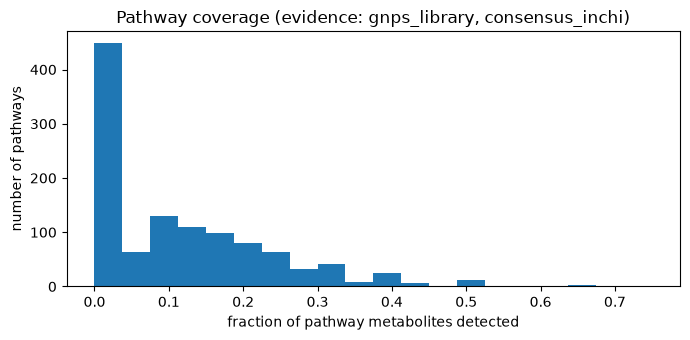

In [16]:
ax = coverage["fraction_detected"].plot.hist(bins=20, figsize=(7, 3.5))
ax.set_xlabel("fraction of pathway metabolites detected")
ax.set_ylabel("number of pathways")
ax.set_title(f"Pathway coverage (evidence: {', '.join(EVIDENCE)})")
plt.tight_layout()

In [17]:
n_any = (coverage["n_detected"] > 0).sum()
say(f"""**Findings** (evidence: {', '.join(EVIDENCE)}; pathways with ≥ {MIN_METABOLITES} metabolites)
- **{n_any}** of **{len(coverage)}** pathways (**{round(100 * n_any / len(coverage))}%**) contain at least one detected metabolite.
- Median fraction of a pathway's metabolites detected: **{coverage['fraction_detected'].median():.2f}**;
  only **{(coverage['fraction_detected'] >= 0.5).sum()}** pathways have half or more of their metabolites detected.""")

**Findings** (evidence: gnps_library, consensus_inchi; pathways with ≥ 3 metabolites)
- **677** of **1123** pathways (**60%**) contain at least one detected metabolite.
- Median fraction of a pathway's metabolites detected: **0.09**;
  only **16** pathways have half or more of their metabolites detected.

**Interpretation**
- Many pathways contain *one* detected metabolite, often a shared precursor such as an amino acid, a sugar or a hydroxycinnamate.
- Few pathways are covered end to end. Pathway intermediates are usually short-lived and present at low levels, so untargeted LC-MS/MS mostly sees end products and hub metabolites.
- Pathways with *several* detected metabolites are the best candidates for linking the Brassicaceae data to PlantMetWiki pathways.

In [18]:
# Search pathways by keyword, e.g. glucosinolate, flavonol, phenylpropanoid, camalexin
KEYWORD = "glucosinolate"
coverage[coverage["pathway"].str.contains(KEYWORD, case=False)].sort_values("fraction_detected", ascending=False)

,plantcyc_id,pathway,n_metabolites,n_detected,fraction_detected
1140,PWYQT-4477,indole glucosinolate activation (intact plant cell),13,3,0.23
745,PWY-6684,aromatic glucosinolate activation,9,2,0.22
1139,PWYQT-4476,indole glucosinolate activation (herbivore attack),18,4,0.22
310,PWY-5267,glucosinolate activation,10,2,0.20
1134,PWYQT-4471,glucosinolate biosynthesis from dihomomethionine,26,5,0.19
138,PWY-2821,glucosinolate biosynthesis from phenylalanine,28,5,0.18
555,PWY-601,glucosinolate biosynthesis from tryptophan,24,4,0.17
1136,PWYQT-4473,glucosinolate biosynthesis from tetrahomomethionine,18,3,0.17
1137,PWYQT-4474,glucosinolate biosynthesis from pentahomomethionine,18,3,0.17
90,PWY-1187,glucosinolate biosynthesis from homomethionine,27,4,0.15


**Comment.** The glucosinolate pathways are only 15–25% covered. The detected metabolites are:
- co-substrates: UDP-glucose, glutathione, glutamate
- amino-acid precursors: phenylalanine, tryptophan
- end products: glucotropaeolin, glucoerucin, glucoraphanin

The intermediates (chain-elongated amino acids, aldoximes, thiohydroximates, desulfoglucosinolates) are short-lived and are not detected.
Glucobrassicin, the end product of the indole pathway, is missing because it has no InChIKey match in PlantMetWiki (see section 11).

## 9. Coverage per species

The number of PlantMetWiki metabolites detected in each of the 14 species. A feature counts for a species if it has non-zero abundance there.

In [19]:
def per_species(tiers):
    sub = hits[hits["tier"].isin(tiers)][["key14", "species"]].copy()
    sub["species"] = sub["species"].str.split(", ")
    sub = sub.explode("species").query("species != ''")
    return sub.groupby("species")["key14"].nunique()

species_cov = pd.DataFrame({"strong tiers": per_species(STRONG_TIERS),
                            "all detection tiers": per_species(DETECTION_TIERS)}).fillna(0).astype(int)
species_cov.sort_values("all detection tiers", ascending=False)

,strong tiers,all detection tiers
species,,
Aethionema arabicum,72,331
Camelina sativa,68,306
Arabidopsis thaliana,66,286
Barbarea vulgaris,55,277
Cardamine hirsuta,59,275
Isatis tinctoria,65,274
Capsella rubella,62,262
Eruca vesicaria,54,248
Lepidium sativum,55,245


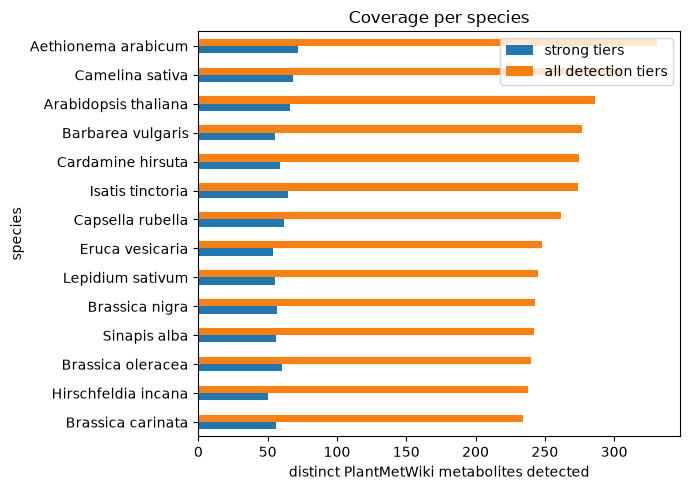

In [20]:
ax = species_cov.sort_values("all detection tiers").plot.barh(figsize=(7, 5))
ax.set_xlabel("distinct PlantMetWiki metabolites detected")
ax.set_title("Coverage per species")
plt.tight_layout()

In [21]:
s = species_cov["all detection tiers"]
say(f"""**Findings**
- Coverage is similar across species: **{s.min()}–{s.max()}** PlantMetWiki metabolites per species (all tiers),
  **{species_cov['strong tiers'].min()}–{species_cov['strong tiers'].max()}** with strong evidence.
- Highest: *{s.idxmax()}*; lowest: *{s.idxmin()}*.""")

**Findings**
- Coverage is similar across species: **234–331** PlantMetWiki metabolites per species (all tiers),
  **50–72** with strong evidence.
- Highest: *Aethionema arabicum*; lowest: *Brassica carinata*.

**Interpretation**
- Most matched metabolites belong to metabolism shared by all Brassicaceae (primary metabolism, sinapate esters, flavonols), so differences between species are small.
- This analysis does **not** yet check whether PlantMetWiki records the pathway *for that species*. That species-aware matching is a next step, and it will show which detections are new for a species or genus.

## 10. Primary vs specialized (secondary) metabolism

PlantMetWiki keeps PlantCyc's most specific pathway class (e.g. `FLAVONOL-SYN`, `Fatty-acid-biosynthesis`) but not the class hierarchy.
The MetaCyc hierarchy that PlantCyc uses is not openly queryable (BioCyc requires an account).
So the ~400 classes are mapped by hand in [`data/pathway_class_categories.csv`](data/pathway_class_categories.csv), following the MetaCyc hierarchy.
**Edit that file to refine the mapping** and re-run the notebook.

| Category | Classes |
|---|---|
| specialized (secondary) | under MetaCyc *Secondary Metabolite Biosynthesis*: alkaloids, phenylpropanoids, flavonoids, terpenoids (incl. carotenoids), glucosinolates, lignin, phytoalexins, ... |
| hormones | plant hormone biosynthesis / inactivation / degradation |
| primary | amino acids, nucleotides, cofactors, carbohydrates, lipids and fatty acids, energy, ... |
| super-pathway / cluster | `Super-Pathways`, `Metabolic-Clusters` (regroup other pathways; ignored below) |
| unclassified | classes too broad to decide, e.g. `ISOPRENOIDS`, `Pigment-Biosynthesis`, `Glycosylation-Pathways` |

A pathway with several classes gets the first matching category in the order of this table.
Each **metabolite** is then labelled by the pathways it occurs in (hormones count as specialized):
- *primary only*
- *specialized only*
- *primary + specialized*: it occurs in both, e.g. a branch-point metabolite such as phenylalanine or 4-coumarate

In [22]:
display(pathway_classes["category"].value_counts().to_frame("PlantCyc pathways"))
# Pathways that stayed 'unclassified' (only broad classes)
pathway_classes.loc[pathway_classes["category"] == "unclassified", "classes"].value_counts().to_frame("unclassified pathways")

,PlantCyc pathways
category,
primary,553
specialized (secondary),514
hormones,57
unclassified,29
super-pathway / cluster,9


,unclassified pathways
classes,
AROMATIC-COMPOUNDS-BIOSYN,8
Activation,3
Other-Degradation,2
Metabolic-Regulators,2
Interconversion,2
Other-biosynthesis,2
AROMATIC-COMPOUNDS-DEGRADATION,2
ISOPRENOIDS,2
MISCELLANEOUS-DEG,1


### Are the matches mostly primary or specialized?

We compare the matched metabolites against the background of **all** PlantMetWiki metabolites.
If a class is over-represented among the matches, the data (and the annotation tools) favour it.

In [23]:
ORDER = ["primary only", "primary + specialized", "specialized only"]

def class_share(keys):
    return metabolite_class.reindex(list(keys))["metabolism_class"].fillna("no pathway class").value_counts()

comparison = pd.DataFrame({
    "all PlantMetWiki": class_share(pmw.index),
    "matched (all detection tiers)": class_share(per_met.index),
    "matched (strong tiers)": class_share(per_met.index[per_met["best_tier"].isin(STRONG_TIERS)]),
}).reindex(ORDER + ["no pathway class"]).fillna(0).astype(int)
comparison_pct = (100 * comparison / comparison.sum()).round(1)
pd.concat({"metabolites": comparison, "%": comparison_pct}, axis=1)

metabolites                                                                     %                                                     
                      all PlantMetWiki matched (all detection tiers) matched (strong tiers) all PlantMetWiki matched (all detection tiers) matched (strong tiers)
metabolism_class                                                                                                                                                 
primary only                       748                           144                     37             27.4                          25.4                   26.6
primary + specialized              233                            82                     35              8.5                          14.5                   25.2
specialized only                  1368                           307                     63             50.1                          54.1                   45.3
no pathway class                   383                            34                      4             14.0                           6.0                    2.9

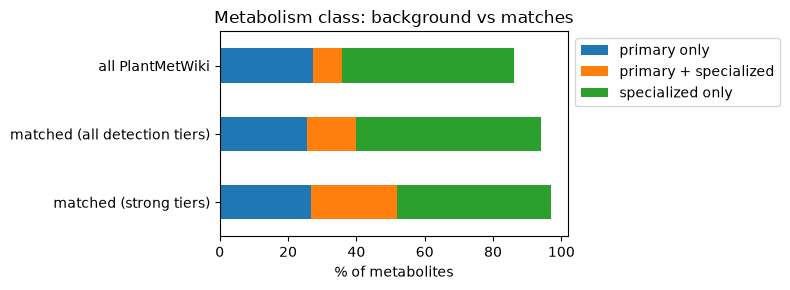

In [24]:
ax = comparison_pct.loc[ORDER].T.plot.barh(stacked=True, figsize=(8, 3))
ax.invert_yaxis()
ax.set_xlabel("% of metabolites")
ax.set_title("Metabolism class: background vs matches")
ax.legend(bbox_to_anchor=(1, 1), loc="upper left")
plt.tight_layout()

In [25]:
bg, st, al = comparison_pct["all PlantMetWiki"], comparison_pct["matched (strong tiers)"], comparison_pct["matched (all detection tiers)"]
say(f"""**Findings**
- The matches are **not dominated by primary metabolism**. Among strongly supported matches:
  - **{st['specialized only']}%** of metabolites occur only in specialized pathways
  - **{st['primary only']}%** occur only in primary pathways
  - **{st['primary + specialized']}%** occur in both
- Compared with all of PlantMetWiki ({bg['specialized only']}% / {bg['primary only']}% / {bg['primary + specialized']}%), the share of
  specialized-only metabolites is similar. Metabolites in **both** are **{st['primary + specialized'] / bg['primary + specialized']:.1f}×
  over-represented** among strong matches ({al['primary + specialized'] / bg['primary + specialized']:.1f}× with all tiers).""")

**Findings**
- The matches are **not dominated by primary metabolism**. Among strongly supported matches:
  - **45.3%** of metabolites occur only in specialized pathways
  - **26.6%** occur only in primary pathways
  - **25.2%** occur in both
- Compared with all of PlantMetWiki (50.1% / 27.4% / 8.5%), the share of
  specialized-only metabolites is similar. Metabolites in **both** are **3.0×
  over-represented** among strong matches (1.7× with all tiers).

**Interpretation**
- **PlantMetWiki itself is half specialized metabolism.** PlantCyc curates many specialized pathways. A match rate of about 50% specialized therefore reflects the database as much as the plants.
- **What the over-represented "both" group contains** (see the list below). There are two kinds of metabolite:
  - *Branch points* where primary metabolism feeds into specialized metabolism: phenylalanine, tyrosine and tryptophan, methionine (a precursor of aliphatic glucosinolates), and the hydroxycinnamates cinnamate, 4-coumarate, caffeate and ferulate.
  - *Ubiquitous co-substrates* that PlantCyc also lists in some specialized pathways: UDP-glucose, glutathione, glutamate, sucrose and organic acids.

  Both kinds are abundant, conserved across species and well represented in spectral libraries, so they are identified with confidence.
- **The specialized-only matches** are mainly phenylpropanoids and flavonoids, plus glucosinolates. That fits Brassicaceae chemistry.

**Caveats**
- The label comes from which PlantCyc pathways a metabolite is in, so it depends on how PlantCyc is curated. For example, D-glucarate counts as specialized because in PlantCyc it only occurs in a caffeoylglucarate pathway.
- Following MetaCyc, carotenoids and lignin count as specialized. Other definitions of "specialized metabolism" would count them as primary.
- 14 very broad classes are left unclassified (see the table above).

In [26]:
# Strongly supported metabolites that occur in both primary and specialized pathways
per_met[(per_met["metabolism_class"] == "primary + specialized") & per_met["best_tier"].isin(STRONG_TIERS)][
    ["pmw_names", "best_tier", "n_pathways"]]

,pmw_names,best_tier,n_pathways
key14,,,
HSCJRCZFDFQWRP,UDP-α-D-galactose | UDP-α-D-glucose,gnps_library,418
RWSXRVCMGQZWBV,glutathione,gnps_library,106
OUYCCCASQSFEME,L-tyrosine,gnps_library,61
QIVBCDIJIAJPQS,D-tryptophan | L-tryptophan,gnps_library,50
KRKNYBCHXYNGOX,citrate,gnps_library,48
ODKSFYDXXFIFQN,L-arginine,gnps_library,44
OIRDTQYFTABQOQ,adenosine,gnps_library,32
WUUGFSXJNOTRMR,S-methyl-5'-thioadenosine,gnps_library,22
QAIPRVGONGVQAS,cis-caffeate | trans-caffeate,gnps_library,18


In [27]:
# Does the class composition differ between evidence tiers?
tier_class = (hits[hits["tier"].isin(DETECTION_TIERS)][["tier", "key14"]].drop_duplicates()
              .join(metabolite_class, on="key14")
              .fillna({"metabolism_class": "no pathway class"}))
pd.crosstab(tier_class["tier"], tier_class["metabolism_class"], normalize="index").reindex(DETECTION_TIERS)[ORDER].mul(100).round(1)

metabolism_class,primary only,primary + specialized,specialized only
tier,,,
gnps_library,21.4,21.4,55.4
consensus_inchi,29.8,28.1,39.5
sirius,22.7,20.9,51.2
ms2query_exact,26.1,17.8,49.3
dreams,26.9,17.6,50.6


**Comment.** The class composition is broadly similar across tiers. The consensus tier has the most metabolites in both primary and specialized pathways,
because tools agree most easily on common hub metabolites.

### Specialized pathways: which classes are covered?

Coverage per specialized-metabolism class (the most specific PlantCyc class), using the evidence chosen in section 8.

In [28]:
spec = coverage.merge(pathway_classes, left_on="plantcyc_id", right_index=True)
spec = spec[spec["category"] == "specialized (secondary)"].assign(cls=lambda d: d["classes"].str.split(", ")).explode("cls")
class_map = pd.read_csv(m.CLASS_CATEGORIES).set_index("class")["category"]
spec = spec[spec["cls"].map(class_map) == "specialized (secondary)"]   # drop co-assigned classes like Super-Pathways
spec_classes = (spec.groupby("cls")
 .agg(pathways=("plantcyc_id", "nunique"),
      pathways_with_detection=("n_detected", lambda s: (s > 0).sum()),
      mean_fraction_detected=("fraction_detected", "mean"))
 .round(2)
 .sort_values("pathways_with_detection", ascending=False))
spec_classes.head(30)

,pathways,pathways_with_detection,mean_fraction_detected
cls,,,
FLAVONOL-SYN,33,27,0.12
ANTHOCYANIN-SYN,28,25,0.20
ALKALOIDS-SYN,17,13,0.12
COUMARIN-SYN,15,13,0.17
ISOFLAVONOID-SYN,28,12,0.11
CINNAMATE-SYN,13,12,0.26
FLAVONE-SYN,15,11,0.13
TRITERPENOID-SYN,22,10,0.10
LIGNAN-SYN,11,9,0.15


In [29]:
top = spec_classes.head(6).index.tolist()
say(f"**Finding.** The specialized classes with the most pathways containing a detection are: {', '.join(f'`{c}`' for c in top)}.")

**Finding.** The specialized classes with the most pathways containing a detection are: `FLAVONOL-SYN`, `ANTHOCYANIN-SYN`, `ALKALOIDS-SYN`, `COUMARIN-SYN`, `ISOFLAVONOID-SYN`, `CINNAMATE-SYN`.

**Interpretation**
- Flavonoid, anthocyanin, coumarin and hydroxycinnamate (cinnamate) pathways are well covered, as expected for Brassicaceae leaves and roots.
- Detections in classes typical of *other* plant families (isoflavonoids, betalains, various alkaloids) come from shared precursors or common flavonoid scaffolds. They don't mean those pathways run in Brassicaceae.
- Species-aware matching (next step) is needed to separate these cases.

In [30]:
# Specialized-only metabolites detected with strong evidence
per_met[(per_met["metabolism_class"] == "specialized only") & per_met["best_tier"].isin(STRONG_TIERS)][
    ["pmw_names", "best_tier", "tiers", "modes", "species"]]

,pmw_names,best_tier,tiers,modes,species
key14,,,,,
OVSQVDMCBVZWGM,quercetin-3-O-β-D-glucoside,gnps_library,"gnps_library, consensus_inchi, sirius, ms2query_exact, dreams","neg, pos","Aethionema arabicum, Barbarea vulgaris, Brassica carinata, Brassica nigra, B..."
MATGKVZWFZHCLI,(-)-matairesinol,gnps_library,"gnps_library, consensus_inchi, ms2query_exact, dreams",pos,"Aethionema arabicum, Barbarea vulgaris, Camelina sativa, Eruca vesicaria, Le..."
RODXRVNMMDRFIK,scopoletin,gnps_library,"gnps_library, consensus_inchi, sirius, ms2query_exact, dreams","neg, pos","Aethionema arabicum, Arabidopsis thaliana, Brassica carinata, Brassica nigra..."
PCMORTLOPMLEFB,sinapate,gnps_library,"gnps_library, consensus_inchi, sirius, ms2query_exact, dreams","neg, pos","Aethionema arabicum, Arabidopsis thaliana, Barbarea vulgaris, Brassica carin..."
XRKBRPFTFKKHEF,1-O-sinapoyl-β-D-glucose,gnps_library,"gnps_library, sirius, ms2query_exact","neg, pos","Aethionema arabicum, Arabidopsis thaliana, Barbarea vulgaris, Brassica carin..."
RDFLLVCQYHQOBU,"cyanidin 3,5-di-O-β-D-glucoside",gnps_library,gnps_library,"neg, pos","Aethionema arabicum, Arabidopsis thaliana, Barbarea vulgaris, Brassica carin..."
AAWZDTNXLSGCEK,L-quinate,gnps_library,"gnps_library, sirius, ms2query_exact",neg,"Brassica carinata, Brassica oleracea, Camelina sativa"
CWVRJTMFETXNAD,chlorogenate,gnps_library,"gnps_library, consensus_inchi, sirius, ms2query_exact, dreams","neg, pos","Aethionema arabicum, Arabidopsis thaliana, Barbarea vulgaris, Brassica carin..."
JYXSWDCPHRTYGU,kaempferol-3-O-β-D-glucopyranoside-7-O-α-L-rhamnopyranoside,gnps_library,"gnps_library, sirius, dreams","neg, pos","Aethionema arabicum, Arabidopsis thaliana, Barbarea vulgaris, Brassica olera..."


## 11. Gaps: library-identified compounds that are NOT in PlantMetWiki

GNPS library matches are the most reliable identifications in the dataset, so those without a PlantMetWiki counterpart are candidate gaps.

In [31]:
lib_names = pd.concat(
    [pd.DataFrame({"mode": mode,
                   "key14": df["library_InChI"].map(m.inchi_to_key14),
                   "library_compound_name": df["library_compound_name"].str.replace(r"^\S+:\S+ ", "", regex=True)})
     for mode, df in tables.items()]
).dropna(subset=["key14"])
lib_names["in_plantmetwiki"] = lib_names["key14"].isin(set(pmw.index))

gaps = (lib_names[~lib_names["in_plantmetwiki"]]
        .groupby("key14")
        .agg(library_compound_name=("library_compound_name", "first"),
             n_features=("library_compound_name", "size"),
             modes=("mode", lambda s: ", ".join(sorted(set(s)))))
        .sort_values("n_features", ascending=False))
n_in = lib_names.loc[lib_names["in_plantmetwiki"], "key14"].nunique()
say(f"**Finding.** **{len(gaps)}** distinct library-identified structures are **not** in PlantMetWiki; **{n_in}** are.")
gaps.head(40)

**Finding.** **129** distinct library-identified structures are **not** in PlantMetWiki; **56** are.

,library_compound_name,n_features,modes
key14,,,
WTCVROXOIQEIRC,"NCGC00385084-01_C23H32O15_alpha-D-Glucopyranoside, 3-O-[(2E)-3-(4-hydroxy-3,...",8,pos
QURCVMIEKCOAJU,Spectral Match to 3-Hydroxy-4-methoxycinnamic acid from NIST14,6,pos
FHIJMQWMMZEFBL,"[(2R,3S,4S,5R,6R)-3,4,5-trihydroxy-6-[(2S,3S,4R,5R)-4-hydroxy-3-[(E)-3-(4-hy...",6,neg
GAPDDBFHNYHZIS,(2R)-2-Hydroxy-2-phenethylglucosinolate,5,neg
RNDGJCZQVKFBPI,"Flavone base + 4O, O-MalonylHex",4,"neg, pos"
SPJFYYJXNPEZDW,LPC 18:2,4,"neg, pos"
DDELFAUOHDSZJL,Kaempferol-3-Glucoside-2''-Rhamnoside-7-Rhamnoside|Kaem-3-Glc-2''-Rha-7-Rha|...,4,pos
DNDNWOWHUWNBCK,Indolylmethyl glucosinolate,4,neg
PEFASEPMJYRQBW,kaempferol-3-O-robinoside-7-O-rhamnoside|Robinin|Kaem_3_Rob__7_Rha|5-hydroxy...,3,neg


In [32]:
# Two glucosinolate examples
EXAMPLES = {"glucosinalbin (p-hydroxybenzyl glucosinolate)": "WWBNBPSEKLOHJU",
            "glucobrassicin (indolylmethyl glucosinolate)": "DNDNWOWHUWNBCK"}
pd.DataFrame({name: {"library match in data": key in set(lib_names["key14"]),
                     "in PlantMetWiki (with InChIKey)": key in pmw.index}
              for name, key in EXAMPLES.items()}).T

,library match in data,in PlantMetWiki (with InChIKey)
glucosinalbin (p-hydroxybenzyl glucosinolate),True,False
glucobrassicin (indolylmethyl glucosinolate),True,False


**Comments**
- Many gaps are glycosylated or acylated flavonoids and hydroxycinnamates, lysophospholipids, and Brassicaceae glucosinolates.
- **Glucosinalbin** (typical of *Sinapis alba*) is identified by library match but is not a PlantMetWiki metabolite.
- **Glucobrassicin** also shows up as a gap, although PlantMetWiki has *desulfo*glucobrassicin and the indole glucosinolate pathway.
  Before reporting a gap, check whether the compound is present in PlantMetWiki without an InChIKey (~10% of metabolites) or under a different charge state.
- Some library names are generic spectral annotations (e.g. "Flavone base + 4O, O-MalonylHex"), and their structure is only an approximation.
- The curated gap list could be fed back to PlantMetWiki/PlantCyc as candidate additions.

## 12. Look up a metabolite

In [33]:
def lookup(text):
    """Search matched PlantMetWiki metabolites by name (case-insensitive)."""
    return per_met[per_met["pmw_names"].str.contains(text, case=False, na=False)][
        ["pmw_names", "best_tier", "tiers", "metabolism_class", "n_features", "modes", "species", "wikidata"]]

lookup("sinapo")

,pmw_names,best_tier,tiers,metabolism_class,n_features,modes,species,wikidata
key14,,,,,,,,
XRKBRPFTFKKHEF,1-O-sinapoyl-β-D-glucose,gnps_library,"gnps_library, sirius, ms2query_exact",specialized only,25,"neg, pos","Aethionema arabicum, Arabidopsis thaliana, Barbarea vulgaris, Brassica carin...",http://www.wikidata.org/entity/Q27101966
HUJXHFRXWWGYQH,O-sinapoylcholine,gnps_library,"gnps_library, ms2query_exact",specialized only,6,pos,"Brassica carinata, Brassica nigra, Brassica oleracea, Lepidium sativum, Sina...",http://www.wikidata.org/entity/Q891772
KQDOTXAUJBODDM,"1,2-di-O-sinapoyl-β-D-glucose",consensus_inchi,"consensus_inchi, sirius, ms2query_exact",specialized only,8,neg,"Aethionema arabicum, Arabidopsis thaliana, Brassica nigra, Cardamine hirsuta...",http://www.wikidata.org/entity/Q27103449
XQQYFEOTBHJJDK,2-O-sinapoyl-D-glucarate,sirius,sirius,specialized only,8,neg,"Barbarea vulgaris, Eruca vesicaria, Isatis tinctoria",http://www.wikidata.org/entity/Q27126056


## 13. Summary

In [34]:
say(f"""
- **Coverage.** The Brassicaceae LC-MS/MS data detect **{c['consensus_inchi']}** PlantMetWiki metabolites with strong evidence
  (library or consensus; {p['consensus_inchi']}% of PlantMetWiki), and **{c.iloc[-1]}** when single-tool predictions are included ({p.iloc[-1]}%).
- **Evidence matters.** {round(100 * n1 / len(per_met))}% of matched metabolites rest on a single tier, so the evidence tier should be kept on every link.
- **Pathways.** {n_any} of {len(coverage)} PlantCyc pathways (≥ {MIN_METABOLITES} metabolites) contain a strongly supported detection,
  but few are covered end to end.
- **Primary vs specialized.** Matches are not dominated by primary metabolism: {st['specialized only']}% specialized only,
  {st['primary only']}% primary only, and {st['primary + specialized']}% in both (strong tiers). Metabolites in both are
  {st['primary + specialized'] / bg['primary + specialized']:.1f}× over-represented.
- **Gaps.** {len(gaps)} library-identified structures are not in PlantMetWiki, e.g. glucosinalbin. These are candidates to curate.
""")


- **Coverage.** The Brassicaceae LC-MS/MS data detect **139** PlantMetWiki metabolites with strong evidence
  (library or consensus; 5.1% of PlantMetWiki), and **567** when single-tool predictions are included (20.8%).
- **Evidence matters.** 59% of matched metabolites rest on a single tier, so the evidence tier should be kept on every link.
- **Pathways.** 677 of 1123 PlantCyc pathways (≥ 3 metabolites) contain a strongly supported detection,
  but few are covered end to end.
- **Primary vs specialized.** Matches are not dominated by primary metabolism: 45.3% specialized only,
  26.6% primary only, and 25.2% in both (strong tiers). Metabolites in both are
  3.0× over-represented.
- **Gaps.** 129 library-identified structures are not in PlantMetWiki, e.g. glucosinalbin. These are candidates to curate.


**Caveats**
- Matching ignores stereochemistry and charge, so isomers can merge.
- PlantMetWiki metabolites without an InChIKey can't be matched.
- The primary/specialized mapping is curated by hand.
- Species are not yet taken into account.

**Next steps**
- [ ] Species-aware matching: is the pathway recorded in PlantMetWiki for the same species or genus?
- [ ] Stereo-aware matching (full InChIKey) as a stricter variant.
- [ ] Curate the gap list: real gaps vs. metabolites without an InChIKey.
- [ ] Review `data/pathway_class_categories.csv`, or add the PlantCyc class hierarchy to PlantMetWiki.
- [ ] Express the matches as RDF with ECO evidence terms per tier (see the main README).